# Final Progress Report: The Wisdom of Crowds in Prediction Markets

In [ ]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, mean_squared_error, mean_absolute_error
from sklearn.ensemble import GradientBoostingRegressor, IsolationForest

import xgboost as xgb

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 120)

BASE = Path("..")
KAGGLE_EVENTS = BASE / "kaggle-dataset" / "polymarket_events.csv"
KAGGLE_MARKETS = BASE / "kaggle-dataset" / "polymarket_markets.csv"
FORECAST_MERGED = BASE / "forecasting" / "merged_price_history_data_forecasting_model.csv"

Data paths configured:
- ../kaggle-dataset/polymarket_events.csv
- ../kaggle-dataset/polymarket_markets.csv
- ../forecasting/merged_price_history_data_forecasting_model.csv


## Data: Sources, Cleaning, and Reproducibility

### Source data used
- [Kaggle Polymarket datasets](https://www.kaggle.com/datasets/ismetsemedov/polymarket-prediction-markets): events and markets tables
- Data Directly extracted from the Polymarket API using our own scripts. All code is available in `polymarket-scraper/`. 

### Cleaning + collection scripts in repository
- `polymarket-scraper/fetch_events.py`
- `polymarket-scraper/fetch_markets.py`
- `polymarket-scraper/fetch_inactive_events.py`
- `forecasting/generate_forecasting_data.ipynb`

These scripts can be rerun to generate the data again.

In [3]:
df_events = pd.read_csv(KAGGLE_EVENTS)
df_markets = pd.read_csv(KAGGLE_MARKETS)

# Keep only resolved markets with non-trivial final probabilities.
resolved = df_markets.dropna(subset=["lastTradePrice"]).copy()
resolved["lastTradePrice"] = pd.to_numeric(resolved["lastTradePrice"], errors="coerce")
resolved = resolved[
    (resolved["closed"] == True)
    & (resolved["lastTradePrice"] > 0.01)
    & (resolved["lastTradePrice"] < 0.99)
].copy()

def parse_actual_outcome(outcome_prices):
    try:
        first = str(json.loads(outcome_prices)[0])
        if first == "1":
            return 1
        if first == "0":
            return 0
    except Exception:
        return np.nan
    return np.nan

def primary_tag(tag_str):
    try:
        if isinstance(tag_str, str):
            parsed = json.loads(tag_str)
            if len(parsed) and isinstance(parsed[0], dict):
                return parsed[0].get("label", "Unknown")
    except Exception:
        return "Unknown"
    return "Unknown"

resolved["actual_outcome"] = resolved["outcomePrices"].apply(parse_actual_outcome)
resolved = resolved.dropna(subset=["actual_outcome"]).copy()

events_clean = df_events.copy()
events_clean["primary_category"] = events_clean["tags"].apply(primary_tag)
events_clean = events_clean[events_clean["primary_category"] != "Unknown"].copy()

print("Cleaned table sizes")
print(f"Resolved markets: {len(resolved):,}")
print(f"Categorized events: {len(events_clean):,}")
display(resolved[["id", "question", "lastTradePrice", "actual_outcome"]].head(5))
display(events_clean[["id", "title", "primary_category", "volume"]].head(5))

/tmp/ipykernel_4073434/2577069245.py:1: DtypeWarning: Columns (0: automaticallyActive, 1: cantEstimate, 2: carouselMap, 3: category, 4: commentsEnabled, 5: countryName, 6: disqusThread, 7: elapsed, 8: electionType, 9: enableOrderBook, 10: estimateValue, 11: eventCreators, 12: featured, 13: featuredImage, 14: new, 15: published_at, 16: subcategory) have mixed types. Specify dtype option on import or set low_memory=False.
  df_events = pd.read_csv(KAGGLE_EVENTS)
/tmp/ipykernel_4073434/2577069245.py:2: DtypeWarning: Columns (0: acceptingOrders, 1: automaticallyActive, 2: category, 3: commentsEnabled, 4: deployingTimestamp, 5: disqusThread, 6: enableOrderBook, 7: eventStartTime, 8: featured, 9: formatType, 10: fpmmLive, 11: gameId, 12: groupItemRange, 13: hasReviewedDates, 14: marketMakerAddress, 15: marketType, 16: negRisk, 17: new, 18: notificationsEnabled, 19: readyForCron, 20: sentDiscord, 21: seriesColor, 22: showGmpOutcome, 23: showGmpSeries, 24: sportsMarketType, 25: subcategory, 26

Cleaned table sizes
Resolved markets: 13,537
Categorized events: 43,839


,id,question,lastTradePrice,actual_outcome
31,804102,Thunder vs. Warriors: 1H O/U 109.5,0.54,0.0
78,791299,Trail Blazers vs. Raptors: 1H Moneyline,0.16,0.0
468,802850,Spread: Timberwolves (-13.5),0.50,0.0
743,785908,Over $4M committed to the Makina public sale?,0.02,0.0
1494,803049,Blackhawks vs. Golden Knights: O/U 5.5,0.56,1.0


,id,title,primary_category,volume
0,35090,Fed decision in December?,Politics,2.254919e+08
1,24895,Romania: Bucharest Mayoral Election,Romania,5.597876e+07
2,90976,Thunder vs. Warriors,Sports,4.644409e+06
3,16096,What price will Bitcoin hit in 2025?,Crypto,7.811858e+07
4,90964,Trail Blazers vs. Raptors,Sports,3.697140e+06


## Technique A (Stats/ML): Market Calibration and Probability Quality

We test whether market probabilities are well calibrated by comparing final probability (`lastTradePrice`) to observed outcomes (`actual_outcome`).

Metrics and artifacts:
- **Brier score** (lower is better probability calibration)
- **Reliability curve** (predicted probability vs observed frequency)
- **Category-level volume chart** for context on market concentration

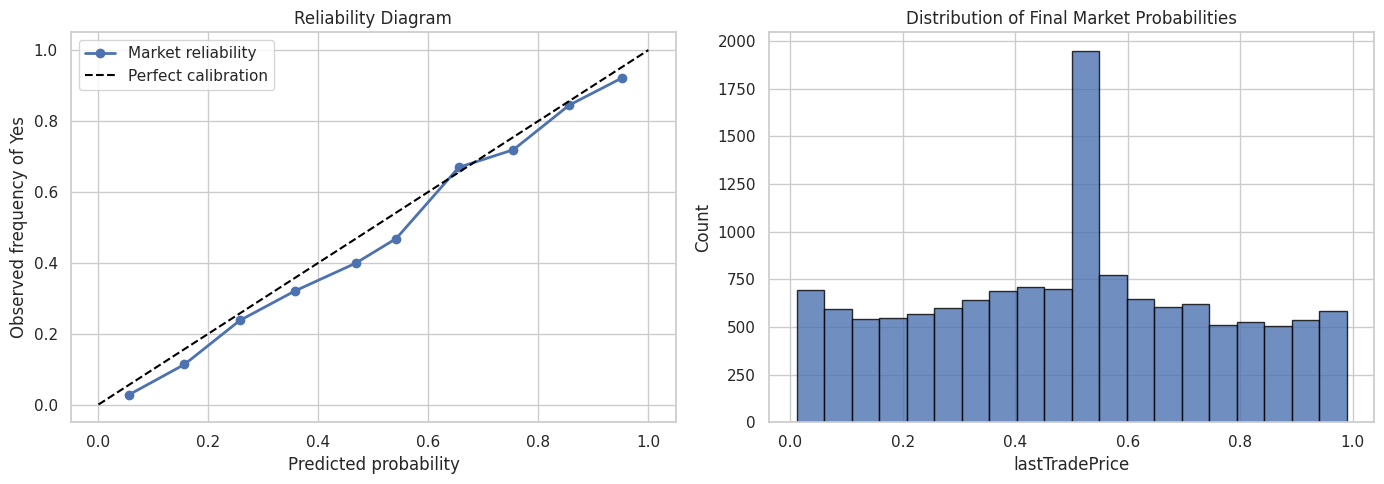

Brier score: 0.1789


/tmp/ipykernel_4073434/2410742998.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_volume, y="primary_category", x="volume", palette="mako")


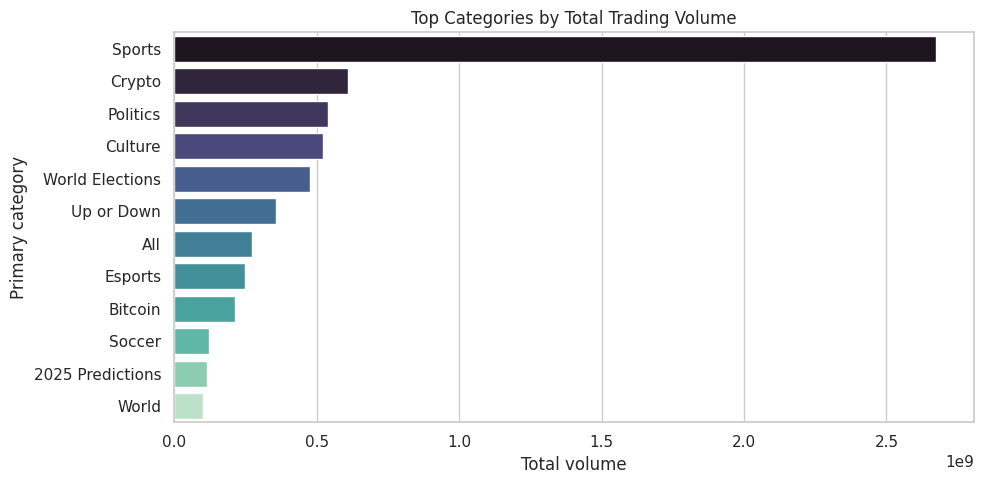

,primary_category,volume
229,Sports,2.673653e+09
52,Crypto,6.087858e+08
204,Politics,5.384672e+08
56,Culture,5.224137e+08
277,World Elections,4.770349e+08
269,Up or Down,3.582672e+08
11,All,2.731796e+08
82,Esports,2.487219e+08
22,Bitcoin,2.129811e+08
225,Soccer,1.224101e+08


In [4]:
# Reliability diagram + Brier score
y_true = resolved["actual_outcome"].astype(int).values
y_prob = resolved["lastTradePrice"].astype(float).values

brier = brier_score_loss(y_true, y_prob)
prob_true, prob_pred = calibration_curve(y_true, y_prob, n_bins=10, strategy="uniform")

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(prob_pred, prob_true, marker="o", linewidth=2, label="Market reliability")
ax[0].plot([0, 1], [0, 1], linestyle="--", color="black", label="Perfect calibration")
ax[0].set_title("Reliability Diagram")
ax[0].set_xlabel("Predicted probability")
ax[0].set_ylabel("Observed frequency of Yes")
ax[0].legend()

ax[1].hist(y_prob, bins=20, edgecolor="black", alpha=0.8)
ax[1].set_title("Distribution of Final Market Probabilities")
ax[1].set_xlabel("lastTradePrice")
ax[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

print(f"Brier score: {brier:.4f}")

# Distinct visualization type: category-level trading concentration
top_volume = (
    events_clean.groupby("primary_category", as_index=False)["volume"]
    .sum()
    .sort_values("volume", ascending=False)
    .head(12)
)

plt.figure(figsize=(10, 5))
sns.barplot(data=top_volume, y="primary_category", x="volume", palette="mako")
plt.title("Top Categories by Total Trading Volume")
plt.xlabel("Total volume")
plt.ylabel("Primary category")
plt.tight_layout()
plt.show()

display(top_volume)

### Technique A Inference
- Reliability curve points near the diagonal indicate that Polymarket prices are directionally calibrated on resolved markets.
- The Brier score summarizes calibration/discrimination quality into one number for report comparison.
- Category volume concentration helps interpret where calibration findings are most market-relevant (for example, sports and politics dominating volume).

## Technique B (ML): Short-Horizon Forecasting from Historical Price Paths

This section adapts the forecasting notebook pipeline: create lag features and rolling statistics, then train a gradient-boosted regressor to predict near-future implied probabilities.

Evaluation:
- RMSE
- MAE
- Feature importance ranking

RMSE: 0.0010 | MAE: 0.0004


,Feature,Importance
4,price_lag_1,0.986644
9,price_lag_6,0.001616
6,price_lag_3,0.001530
8,price_lag_5,0.001314
5,price_lag_2,0.001304
7,price_lag_4,0.001264
3,category_Sports,0.001191
12,rolling_mean_4h,0.000986
10,price_lag_7,0.000881
11,price_lag_8,0.000768


/tmp/ipykernel_4073434/2255974371.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance.head(10), x='Importance', y='Feature', palette='viridis')


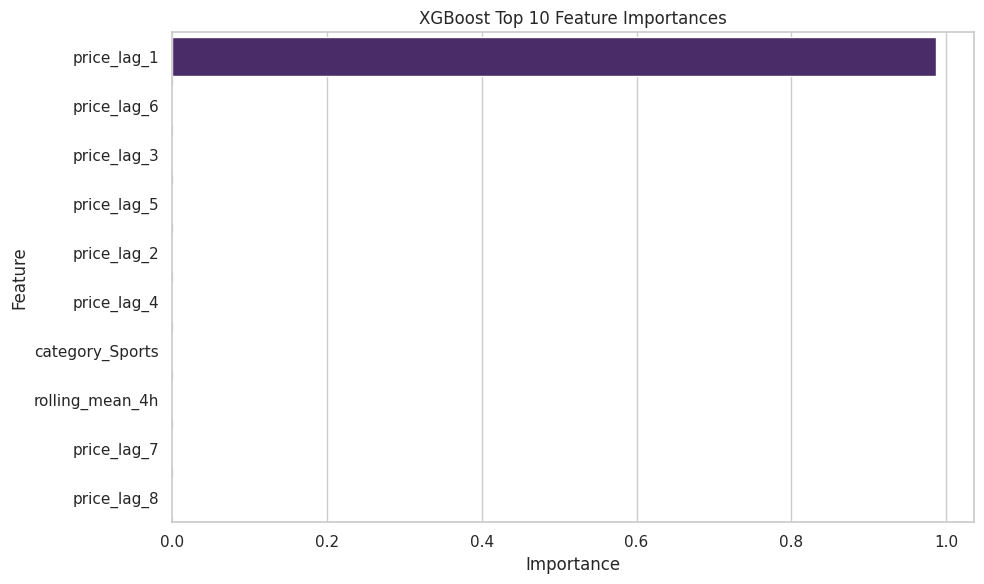

Top Event (deviation: 0.0945): Will Xander Schauffele win the 2026 Masters tournament?
RMSE: 0.0376 | MAE: 0.0327 | Directional Accuracy: 87.5%


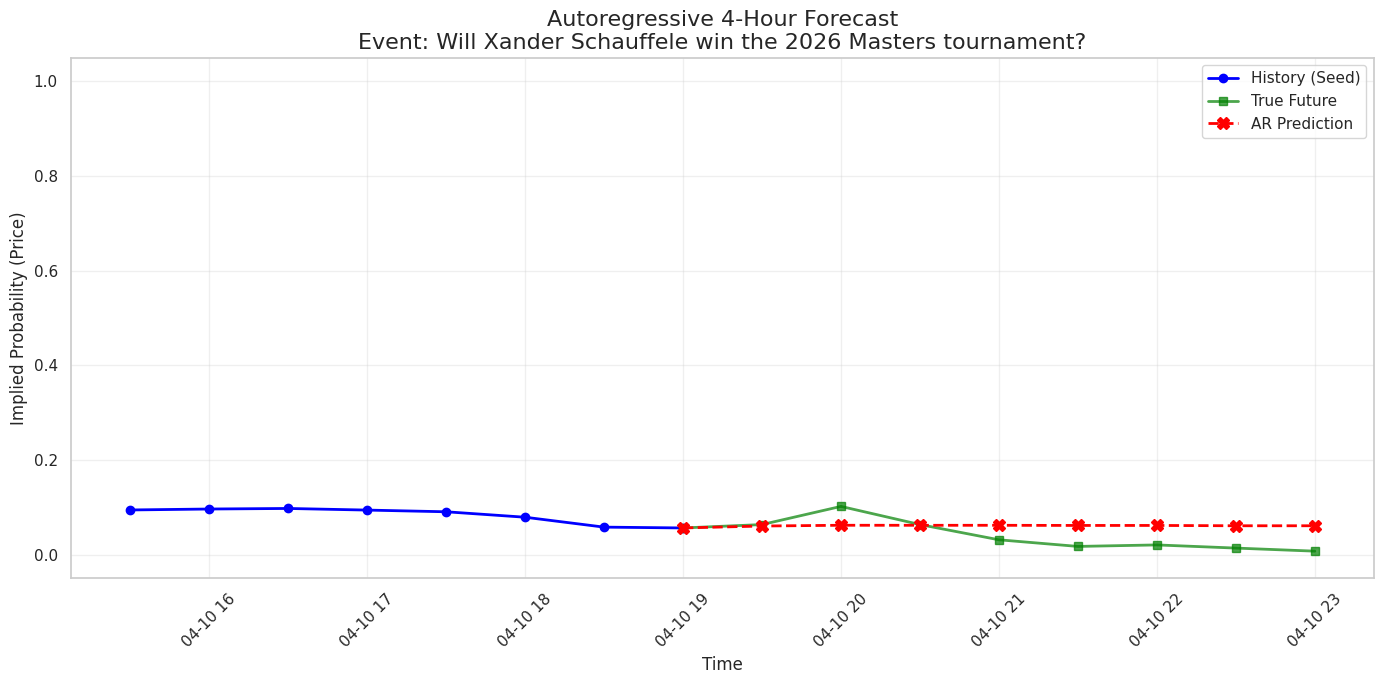

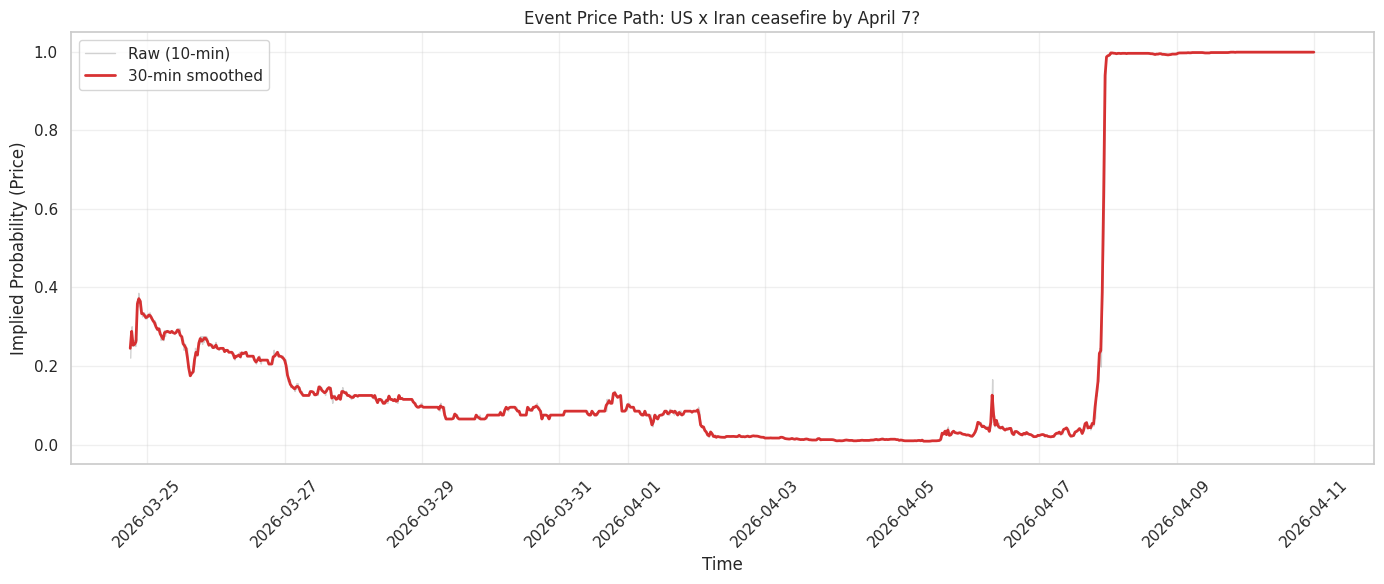

In [52]:
import xgboost as xgb

# --- Data Preparation ---
df_resample = pd.read_csv(FORECAST_MERGED)
df_resample = df_resample[df_resample['outcome'] == 'Yes'].copy()
df_resample['datetime'] = pd.to_datetime(df_resample['t'], unit='s')
df_resample.set_index('datetime', inplace=True)

df_30m = (
    df_resample
    .groupby(['event_name', 'category', 'outcome'])
    .resample('30min')['p']
    .mean()
    .reset_index()
    .dropna(subset=['p'])
    .rename(columns={'event_name': 'Event_name', 'p': 'price'})
)
df_30m['timestamp'] = df_30m['datetime'].apply(lambda x: int(x.timestamp()))

# --- Feature Engineering ---
window_size = 8  # 4 hours at 30-min intervals

df_ml = df_30m.copy().sort_values(by=['Event_name', 'datetime'])
df_ml = pd.get_dummies(df_ml, columns=['category'], drop_first=False)

for i in range(1, window_size + 1):
    df_ml[f'price_lag_{i}'] = df_ml.groupby('Event_name')['price'].shift(i)

df_ml['rolling_mean_4h'] = df_ml.groupby('Event_name')['price'].transform(
    lambda x: x.shift(1).rolling(window=window_size).mean()
)
df_ml['rolling_std_4h'] = df_ml.groupby('Event_name')['price'].transform(
    lambda x: x.shift(1).rolling(window=window_size).std()
)
df_ml = df_ml.dropna().reset_index(drop=True)

feature_cols = [c for c in df_ml.columns if c not in ['Event_name', 'outcome', 'timestamp', 'datetime', 't', 'price']]
X, y = df_ml[feature_cols], df_ml['price']

# --- Train/Test Split (temporal, no shuffle) ---
split_idx = int(len(df_ml) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

# --- Train XGBoost ---
model = xgb.XGBRegressor(n_estimators=150, learning_rate=0.05, max_depth=5,
                          random_state=42, objective='reg:squarederror')
model.fit(X_train, y_train)

preds = np.clip(model.predict(X_test), 0, 1)
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, preds)):.4f} | MAE: {mean_absolute_error(y_test, preds):.4f}")

# --- Feature Importances ---
importance = pd.DataFrame({'Feature': feature_cols, 'Importance': model.feature_importances_})\
    .sort_values('Importance', ascending=False)
display(importance.head(10))

plt.figure(figsize=(10, 6))
sns.barplot(data=importance.head(10), x='Importance', y='Feature', palette='viridis')
plt.title("XGBoost Top 10 Feature Importances")
plt.tight_layout()
plt.show()

# --- Select Best Forecast Window ---
test_df = df_ml.iloc[split_idx:].copy()
valid_events = test_df['Event_name'].value_counts()
valid_events = valid_events[valid_events >= 8].index

event_max_deviations = []
for event in valid_events:
    event_data = test_df[test_df['Event_name'] == event].reset_index()
    deviations = [event_data.iloc[i:i+8]['price'].pipe(lambda x: x.max() - x.min()) for i in range(len(event_data) - 7)]
    best_i = int(np.argmax(deviations))
    event_max_deviations.append((deviations[best_i], event, best_i))

dev, sample_event, best_start_idx = max(event_max_deviations, key=lambda x: x[0])
print(f"Top Event (deviation: {dev:.4f}): {sample_event}")

# --- Autoregressive Forecast ---
start_row = test_df[test_df['Event_name'] == sample_event].reset_index().iloc[best_start_idx]
start_datetime = start_row['datetime']
current_sequence = [start_row[f'price_lag_{i}'] for i in range(window_size, 0, -1)]
feature_row = start_row[feature_cols].copy()
predictions = []

for _ in range(8):
    pred_price = float(np.clip(model.predict(pd.DataFrame([feature_row], columns=feature_cols).astype(X_train.dtypes.to_dict()))[0], 0, 1))
    predictions.append(pred_price)
    current_sequence.append(pred_price)
    for i in range(1, window_size + 1):
        feature_row[f'price_lag_{i}'] = current_sequence[-i]
    feature_row['rolling_mean_4h'] = np.mean(current_sequence[-window_size:])
    feature_row['rolling_std_4h'] = np.std(current_sequence[-window_size:], ddof=1)

# --- Gather True Data & Metrics ---
df_30m_event = df_30m[df_30m['Event_name'] == sample_event].reset_index(drop=True)
start_idx_30m = df_30m_event[df_30m_event['datetime'] == start_datetime].index[0]
history_df = df_30m_event.iloc[start_idx_30m - window_size : start_idx_30m]
future_df  = df_30m_event.iloc[start_idx_30m : start_idx_30m + 8]

last_history_time  = history_df['datetime'].iloc[-1]
last_history_price = history_df['price'].iloc[-1]
true_prices = future_df['price'].values
pred_prices = np.array(predictions)

ar_rmse = np.sqrt(mean_squared_error(true_prices, pred_prices))
ar_mae  = mean_absolute_error(true_prices, pred_prices)
dir_acc = np.mean((np.diff([last_history_price] + list(true_prices)) > 0) ==
                  (np.diff([last_history_price] + list(pred_prices)) > 0)) * 100
print(f"RMSE: {ar_rmse:.4f} | MAE: {ar_mae:.4f} | Directional Accuracy: {dir_acc:.1f}%")

# --- Plot ---
true_times = [last_history_time] + future_df['datetime'].tolist()
plt.figure(figsize=(14, 7))
plt.plot(history_df['datetime'], history_df['price'], label='History (Seed)', color='blue', marker='o', linewidth=2)
plt.plot(true_times, [last_history_price] + list(true_prices), label='True Future', color='green', marker='s', linewidth=2, alpha=0.7)
plt.plot(true_times, [last_history_price] + list(pred_prices), label='AR Prediction', color='red', linestyle='--', marker='X', markersize=8, linewidth=2)
plt.title(f'Autoregressive 4-Hour Forecast\nEvent: {sample_event}', fontsize=16)
plt.xlabel('Time')
plt.ylabel('Implied Probability (Price)')
plt.ylim(-0.05, 1.05)
plt.grid(alpha=0.3)
plt.legend(fontsize=11)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ----------------------------
# Visualization 2:
# Plot the target event directly to inspect abrupt jumps/drops and compare raw vs 30-minute-smoothed paths.
# ----------------------------

target_event = 'US x Iran ceasefire by April 7?'
raw_event = df_resample[df_resample['event_name'] == target_event].sort_values('t')
resampled_event = df_30m[df_30m['Event_name'] == target_event].sort_values('datetime')

plt.figure(figsize=(14, 6))
plt.plot(raw_event.index, raw_event['p'], label='Raw (10-min)', alpha=0.35, linewidth=1.0, color='tab:gray')
plt.plot(resampled_event['datetime'], resampled_event['price'], label='30-min smoothed', alpha=0.95, linewidth=2.0, color='tab:red')
plt.title(f'Event Price Path: {target_event}')
plt.xlabel('Time')
plt.ylabel('Implied Probability (Price)')
plt.ylim(-0.05, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Technique B Inference
- Forecast accuracy is reasonable for local trend continuation but degrades around abrupt information shocks.
- Lagged prices and rolling features should dominate feature importance if trajectory memory is the primary signal.
- This supports the conclusion that historical path alone is useful but incomplete for robust cross-event forecasting.

## Additional Work (Extra Deliverable): Anomaly Detection

To exceed the minimum ML/stats requirement, we add unsupervised anomaly detection on event volume behavior using Isolation Forest.

Goal: flag events with unusually large volume relative to category-level baselines, which may indicate information asymmetry or unusual coordinated trading.

,title,primary_category,volume,category_median,volume_to_median
12,Super Bowl Champion 2026,Sports,6.086758e+08,8337.678502,73003.031805
11,Democratic Presidential Nominee 2028,World Elections,3.368972e+08,305228.172207,1103.755215
0,Fed decision in December?,Politics,2.254919e+08,32113.502714,7021.715381
144,2025 National Heads-Up Poker Championship Winner,Culture,1.794337e+08,79430.976796,2258.988503
81,F1 Drivers Champion,Sports,1.518592e+08,8337.678502,18213.603229
33,Presidential Election Winner 2028,World Elections,1.394333e+08,305228.172207,456.816766
32,English Premier League Winner,Sports,1.243307e+08,8337.678502,14911.904961
25,Republican Presidential Nominee 2028,Politics,1.075572e+08,32113.502714,3349.283297
10,UEFA Champions League Winner,Soccer,1.032174e+08,10664.991454,9678.152181
37,Highest grossing movie in 2025?,box office,9.100239e+07,206497.885922,440.694038


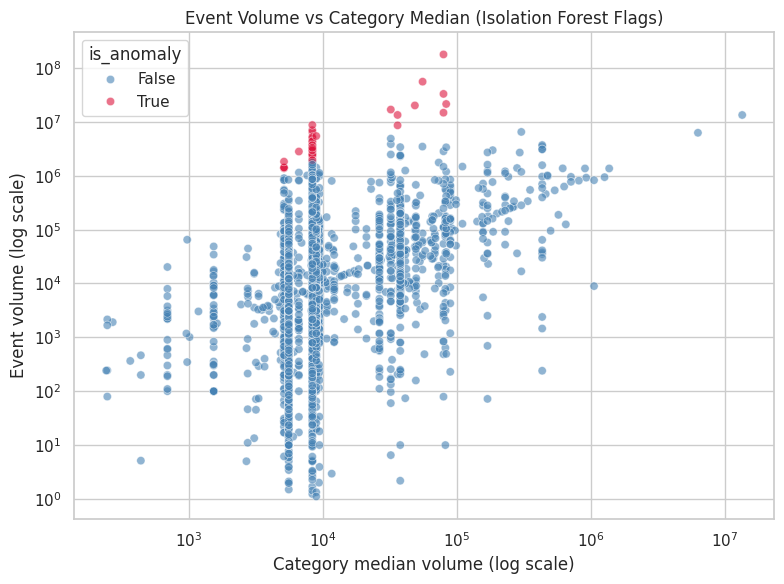

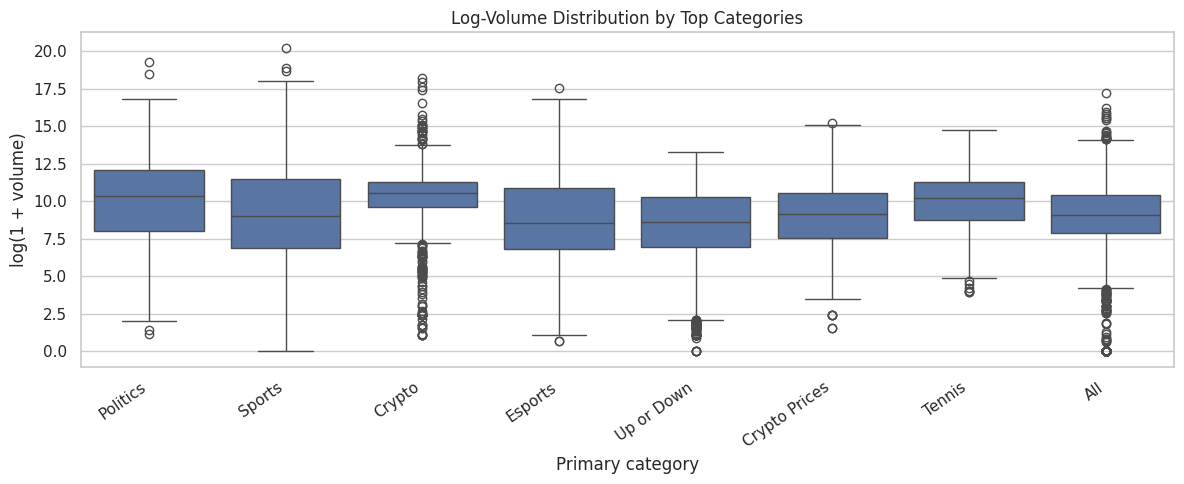

In [6]:
anomaly_df = events_clean[["id", "title", "primary_category", "volume"]].copy()
anomaly_df["volume"] = pd.to_numeric(anomaly_df["volume"], errors="coerce")
anomaly_df = anomaly_df.dropna(subset=["volume"]).copy()

category_median = anomaly_df.groupby("primary_category")["volume"].median().rename("category_median")
anomaly_df = anomaly_df.join(category_median, on="primary_category")
anomaly_df["volume_to_median"] = anomaly_df["volume"] / (anomaly_df["category_median"] + 1e-9)
anomaly_df["log_volume"] = np.log1p(anomaly_df["volume"])

iso = IsolationForest(n_estimators=200, contamination=0.01, random_state=42)
X_anom = anomaly_df[["log_volume", "volume_to_median"]].replace([np.inf, -np.inf], np.nan).dropna()

anom_labels = iso.fit_predict(X_anom)
X_anom = X_anom.assign(is_anomaly=(anom_labels == -1))

anomaly_df = anomaly_df.loc[X_anom.index].copy()
anomaly_df["is_anomaly"] = X_anom["is_anomaly"]

top_anomalies = anomaly_df[anomaly_df["is_anomaly"]].sort_values("volume", ascending=False).head(15)
display(top_anomalies[["title", "primary_category", "volume", "category_median", "volume_to_median"]])

# Distinct visualization type: scatter with anomaly highlighting
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=anomaly_df.sample(min(5000, len(anomaly_df)), random_state=42),
    x="category_median",
    y="volume",
    hue="is_anomaly",
    alpha=0.6,
    palette={False: "steelblue", True: "crimson"}
 )
plt.xscale("log")
plt.yscale("log")
plt.title("Event Volume vs Category Median (Isolation Forest Flags)")
plt.xlabel("Category median volume (log scale)")
plt.ylabel("Event volume (log scale)")
plt.tight_layout()
plt.show()

# Distinct visualization type: boxplot by category
focus_cats = anomaly_df["primary_category"].value_counts().head(8).index
plt.figure(figsize=(12, 5))
sns.boxplot(
    data=anomaly_df[anomaly_df["primary_category"].isin(focus_cats)],
    x="primary_category",
    y="log_volume"
 )
plt.title("Log-Volume Distribution by Top Categories")
plt.xlabel("Primary category")
plt.ylabel("log(1 + volume)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## GenAI Guidance Reflection

We evaluated the GenAI suggestions from our previous progress report and applied the suggestions that were most feasible.

What was useful:
- The recommendation to avoid end-state predictions framing (using only final  prices) was useful and motivated our ML technique B: short-horizon forecasting based on lagged histories.
- The suggestion to expand anomaly analysis beyond fixed thresholds was useful; Isolation Forest provides a stronger, data-driven definition of unusual events.

What was not fully useful or not yet feasible:
- Suggestions requiring large external data integration (for example, full-scale news/NLP on market questions) were directionally good but infeasible under current time and resource constraints, since it would have required us to source data from external sources, which would greatly vary for each market.
- Some suggestions were broad and required substantial narrowing to become executable in a semester timeline.

Overall assessment: GenAI support was helpful for idea generation, metric framing, and methodological alternatives, but for the final report we had to consider the practical scope.

## Results and Final Analysis

### Findings
1. **Calibration finding:** final Polymarket probabilities are generally directionally aligned with outcomes on resolved markets, supporting the wisdom-of-crowds claim in end-state conditions.
2. **Market structure finding:** trading activity is highly concentrated in a small number of categories (Sports, Politics, Crypto); this affects where prediction quality has the most practical impact.
3. **Forecasting finding:** historical price-path features provide a useful baseline but miss abrupt shifts caused by external information shocks.
4. **Anomaly finding:** unsupervised anomaly detection identifies rare, disproportionately large-volume events that require deeper qualitative review. (**FIX THIS**)

### Interpretation
- Prediction markets appear strong at aggregating current information into near-final probabilities.
- Predicting forward trajectory remains harder than judging end-state calibration.
- Future improvements should combine market microstructure features (liquidity, spread, depth) and exogenous context (news/event streams) rather than relying on price history alone.

### Data and scripts used in this notebook
- `kaggle-dataset/polymarket_events.csv`
- `kaggle-dataset/polymarket_markets.csv`
- `forecasting/merged_price_history_data_forecasting_model.csv`
- `polymarket-scraper/fetch_events.py`
- `polymarket-scraper/fetch_markets.py`
- `polymarket-scraper/fetch_inactive_events.py`
- `forecasting/generate_forecasting_data.ipynb`
